In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from ucimlrepo import fetch_ucirepo 

In [2]:
wdbc = fetch_ucirepo(id=17)

X_raw = wdbc.data.features  
y_raw = wdbc.data.targets  
ids   = wdbc.data.ids      

colunas_features = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",

    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",

    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

df = X_raw.copy()
df.columns = colunas_features
df.insert(0, "diagnosis", y_raw.iloc[:, 0].values)
df.insert(0, "id", ids.iloc[:, 0].values)

print(df.shape)
print(df.isnull().sum().sum(), "valores ausentes")

display(df.head())

(569, 32)
0 valores ausentes


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


diagnosis
B    357
M    212
Name: count, dtype: int64

Proporção das classes:
diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64


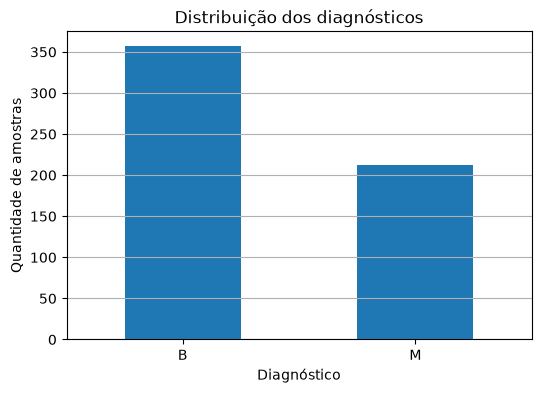

In [3]:
print(df["diagnosis"].value_counts())

print("\nProporção das classes:")
print(df["diagnosis"].value_counts(normalize=True))

df["diagnosis"].value_counts().reindex(["B", "M"]).plot(
    kind="bar",
    figsize=(6, 4)
)

plt.xlabel("Diagnóstico")
plt.ylabel("Quantidade de amostras")
plt.title("Distribuição dos diagnósticos")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [4]:
X = df.drop(columns=["id", "diagnosis"])  
y = df["diagnosis"] 

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Formato de X: (569, 30)
Formato de y: (569,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Treino:", X_train.shape[0], "amostras")
print("Teste: ", X_test.shape[0], "amostras")

print("\nProporção no treinamento:")
print(y_train.value_counts(normalize=True))

print("\nProporção no teste:")
print(y_test.value_counts(normalize=True))

Treino: 455 amostras
Teste:  114 amostras

Proporção no treinamento:
diagnosis
B    0.626374
M    0.373626
Name: proportion, dtype: float64

Proporção no teste:
diagnosis
B    0.631579
M    0.368421
Name: proportion, dtype: float64


In [6]:
scaler = StandardScaler()

X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

In [7]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21]

acuracias_medias = []

for k in valores_k:
    modelo = make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        modelo, X_train, y_train, cv=5, scoring="accuracy"
    )

    acuracias_medias.append(scores.mean())

    print(f"k = {k:2d} -> acurácia média = {scores.mean():.4f}")

k =  1 -> acurácia média = 0.9473
k =  3 -> acurácia média = 0.9670
k =  5 -> acurácia média = 0.9626
k =  7 -> acurácia média = 0.9692
k =  9 -> acurácia média = 0.9670
k = 11 -> acurácia média = 0.9582
k = 15 -> acurácia média = 0.9604
k = 21 -> acurácia média = 0.9560


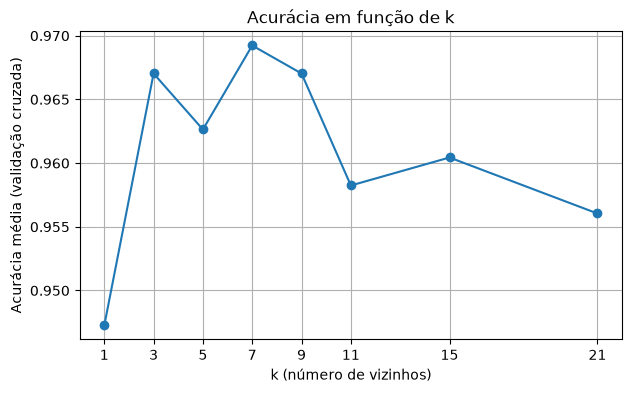

In [8]:
plt.figure(figsize=(7, 4))

plt.plot(valores_k, acuracias_medias, marker="o")

plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("Acurácia em função de k")

plt.xticks(valores_k)
plt.grid(True)

plt.savefig("acuracia_vs_k.png", dpi=150)

plt.show()

In [9]:
melhor_k = valores_k[int(np.argmax(acuracias_medias))]

print("Melhor k:", melhor_k)
print("Melhor acurácia média:", max(acuracias_medias))

Melhor k: 7
Melhor acurácia média: 0.9692307692307693


In [10]:
modelo_final = KNeighborsClassifier(n_neighbors=melhor_k)

modelo_final.fit(X_train_norm, y_train)

y_pred = modelo_final.predict(X_test_norm)

[[38  4]
 [ 1 71]]


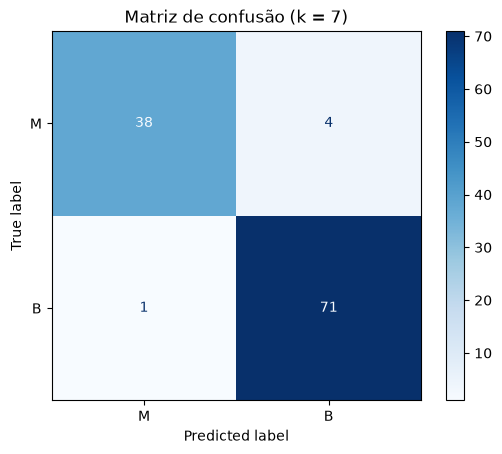

In [11]:
ordem = ["M", "B"]

cm = confusion_matrix(
    y_test, y_pred, labels=ordem
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=ordem
)

disp.plot(cmap="Blues")

plt.title(f"Matriz de confusão (k = {melhor_k})")

plt.savefig("matriz_confusao.png", dpi=150)

plt.show()

In [14]:
print(
    classification_report(y_test, y_pred, labels=ordem, zero_division=0)
)

              precision    recall  f1-score   support

           M       0.97      0.90      0.94        42
           B       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

